# Classification average precision across evaluation splits

Values are manually transcribed from the supplied Section 9 screenshot; no models are fitted. Each line represents a model. CV points show mean ? standard deviation across five folds; Validation and Test (June) are single scores. All values are percentages.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ap_data = pd.DataFrame([
    ('C0', 'No-skill baseline', 9.57, 3.43, 10.38, 2.23),
    ('C1', 'Logistic (all)', 13.83, 2.61, 24.16, 8.06),
    ('C2', 'Logistic (CV-stepwise)', 15.03, 3.52, 23.64, 7.32),
    ('C2B', 'Logistic (BIC)', 14.15, 2.60, 24.04, 8.03),
    ('C3', 'Random Forest (tuned)', 26.91, 3.70, 21.94, 11.22),
    ('C3d', 'Random Forest (default)', 25.26, 4.00, 20.38, 10.97),
], columns=['Code', 'Model', 'CV', 'CV SD', 'Validation', 'Test (June)'])
ap_data


,Code,Model,CV,CV SD,Validation,Test (June)
0,C0,No-skill baseline,9.57,3.43,10.38,2.23
1,C1,Logistic (all),13.83,2.61,24.16,8.06
2,C2,Logistic (CV-stepwise),15.03,3.52,23.64,7.32
3,C2B,Logistic (BIC),14.15,2.60,24.04,8.03
4,C3,Random Forest (tuned),26.91,3.70,21.94,11.22
5,C3d,Random Forest (default),25.26,4.00,20.38,10.97


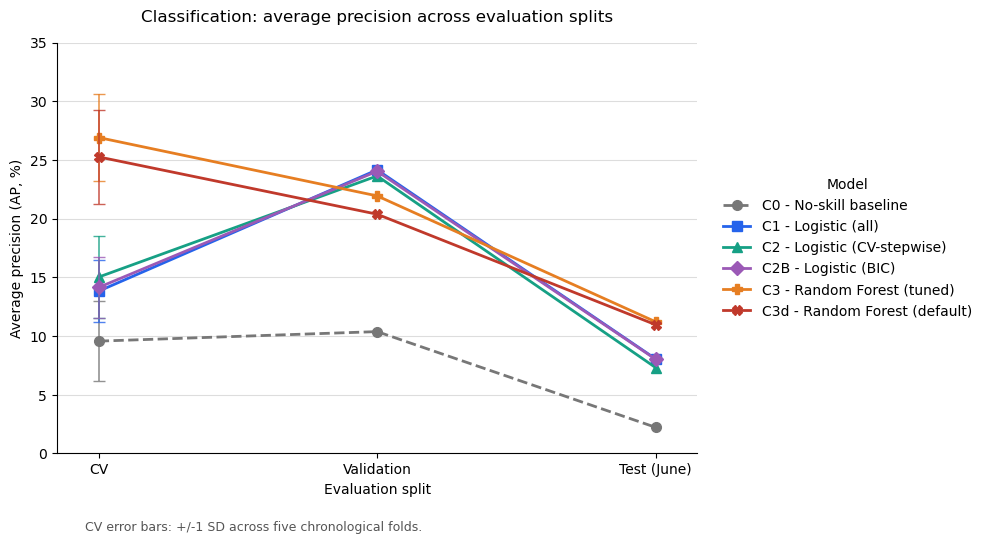

In [2]:
splits = ['CV', 'Validation', 'Test (June)']
colors = ['#777777', '#2563eb', '#16a085', '#9b59b6', '#e67e22', '#c0392b']
markers = ['o', 's', '^', 'D', 'P', 'X']

with plt.rc_context({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'}):
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for (_, row), color, marker in zip(ap_data.iterrows(), colors, markers):
        ax.plot(range(3), row[splits].to_numpy(dtype=float),
                color=color, marker=marker, markersize=7, linewidth=2,
                label=f"{row['Code']} - {row['Model']}",
                linestyle='--' if row['Code'] == 'C0' else '-')
        ax.errorbar(0, row['CV'], yerr=row['CV SD'], color=color,
                    fmt='none', capsize=4, linewidth=1.2, alpha=0.8)
    ax.set_xticks(range(3), splits)
    ax.set_xlim(-0.15, 2.15)
    ax.set_ylim(0, 35)
    ax.set_yticks(range(0, 36, 5))
    ax.set_xlabel('Evaluation split')
    ax.set_ylabel('Average precision (AP, %)')
    ax.set_title('Classification: average precision across evaluation splits', pad=15)
    ax.grid(axis='y', color='#dddddd', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(title='Model', loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.text(0.09, 0.025, 'CV error bars: +/-1 SD across five chronological folds.',
             fontsize=9, color='#555555')
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    output_path = Path('results/simple_to_complex/figures/classification_ap_by_split.png')
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, dpi=200, bbox_inches='tight')
    plt.show()


## Regression RMSE across evaluation splits

Values are manually transcribed from the supplied regression screenshot. Lower RMSE is better. CV error bars show mean +/- one standard deviation across five chronological folds. No models are fitted.

In [3]:
rmse_data = pd.DataFrame([
    ('R0a', 'Median baseline', 9.265, 1.022, 9.964, 11.688),
    ('R0b', 'Olist promise', 14.255, 1.237, 13.550, 20.888),
    ('R1', 'OLS (all)', 8.651, 1.349, 8.205, 7.369),
    ('R2', 'OLS (CV-stepwise)', 8.614, 1.163, 8.926, 9.373),
    ('R2B', 'OLS (BIC)', 8.635, 1.371, 8.204, 7.374),
    ('R3', 'Random Forest (tuned)', 8.310, 0.934, 8.397, 7.953),
    ('R3d', 'Random Forest (default)', 8.710, 1.014, 8.556, 8.393),
], columns=['Code', 'Model', 'CV', 'CV SD', 'Validation', 'Test (June)'])
rmse_data


,Code,Model,CV,CV SD,Validation,Test (June)
0,R0a,Median baseline,9.265,1.022,9.964,11.688
1,R0b,Olist promise,14.255,1.237,13.550,20.888
2,R1,OLS (all),8.651,1.349,8.205,7.369
3,R2,OLS (CV-stepwise),8.614,1.163,8.926,9.373
4,R2B,OLS (BIC),8.635,1.371,8.204,7.374
5,R3,Random Forest (tuned),8.310,0.934,8.397,7.953
6,R3d,Random Forest (default),8.710,1.014,8.556,8.393


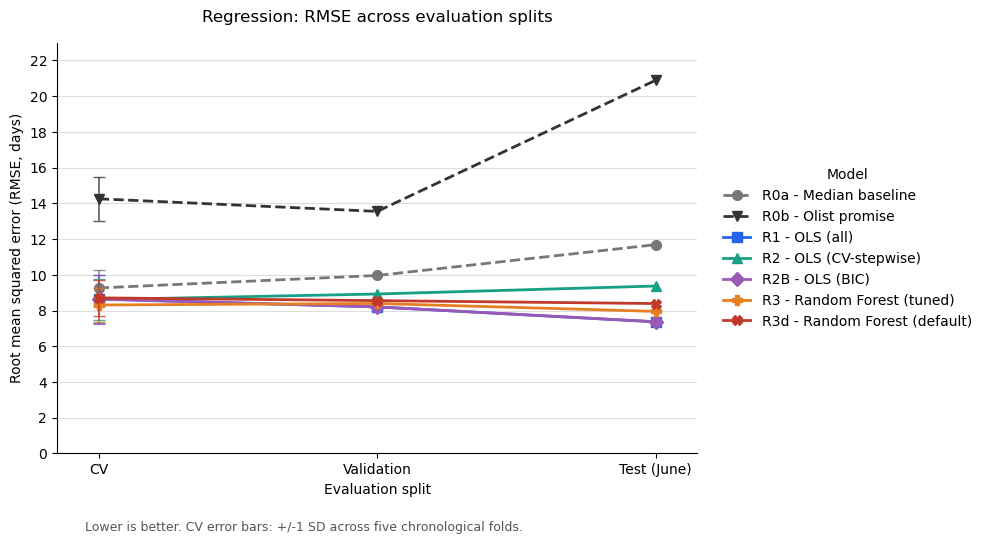

In [4]:
splits = ['CV', 'Validation', 'Test (June)']
rmse_colors = ['#777777', '#333333', '#2563eb', '#16a085', '#9b59b6', '#e67e22', '#c0392b']
rmse_markers = ['o', 'v', 's', '^', 'D', 'P', 'X']

with plt.rc_context({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'}):
    rmse_fig, rmse_ax = plt.subplots(figsize=(10, 5.5))
    for (_, row), color, marker in zip(rmse_data.iterrows(), rmse_colors, rmse_markers):
        rmse_ax.plot(range(3), row[splits].to_numpy(dtype=float),
                     color=color, marker=marker, markersize=7, linewidth=2,
                     label=f"{row['Code']} - {row['Model']}",
                     linestyle='--' if row['Code'] in ('R0a', 'R0b') else '-')
        rmse_ax.errorbar(0, row['CV'], yerr=row['CV SD'], color=color,
                         fmt='none', capsize=4, linewidth=1.2, alpha=0.8)
    rmse_ax.set_xticks(range(3), splits)
    rmse_ax.set_xlim(-0.15, 2.15)
    rmse_ax.set_ylim(0, 23)
    rmse_ax.set_yticks(range(0, 23, 2))
    rmse_ax.set_xlabel('Evaluation split')
    rmse_ax.set_ylabel('Root mean squared error (RMSE, days)')
    rmse_ax.set_title('Regression: RMSE across evaluation splits', pad=15)
    rmse_ax.grid(axis='y', color='#dddddd', linewidth=0.8)
    rmse_ax.set_axisbelow(True)
    rmse_ax.legend(title='Model', loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
    rmse_fig.text(0.09, 0.025, 'Lower is better. CV error bars: +/-1 SD across five chronological folds.',
                  fontsize=9, color='#555555')
    rmse_fig.tight_layout(rect=(0, 0.06, 1, 1))
    rmse_output_path = Path('results/simple_to_complex/figures/regression_rmse_by_split.png')
    rmse_output_path.parent.mkdir(parents=True, exist_ok=True)
    rmse_fig.savefig(rmse_output_path, dpi=200, bbox_inches='tight')
    plt.show()
